# Steam Pulse: What keeps a video game alive?

**Steam** is the biggest online store for PC games, a bit like an App Store for computer games. At any moment it shows how many people are playing each game *right now*.

**The question:** out of about 1,000 of the most popular games on Steam, which ones are people actually playing, and what do the busiest games have in common?

**The data:**
- A live count of players for **1,029 games**, collected from Steam on 12 Oct 2026.
- Each game's store details: price, genre, features (like co-op), and reviews.
- Monthly player history going back to 2012 (from SteamCharts.com) and daily prices from 2019 to 2020 (a public research dataset).

**How to read this notebook:** each section asks one question, shows one chart, and ends with a bold **What this means**. You can skip the small code boxes; they just load data and draw the chart.

> **One term you'll see a lot:** *median* = the middle value. Line all games up from smallest to biggest, and the median is the one in the middle. It's used instead of an average because a few giant games (like Counter-Strike 2) would make an average misleading.

In [1]:
import sys; sys.path.insert(0, "..")   # lets the notebook find the project's helper code
from steam_pulse.story import *        # chart and summary helpers live in steam_pulse/story.py
games = load_games()
print(f"{len(games):,} games, {games['players'].sum():,.0f} people playing at the moment of the snapshot")

1,029 games, 6,222,125 people playing at the moment of the snapshot


## 1. Which games are people playing right now?

On 12 Oct 2026 (9:29 AM CST), about **6.22 million** people were playing one of these 1,029 games. The chart shows the 15 busiest.

Counter-Strike 2, a free team shooter, is in a league of its own with about 1.16 million players, more than the next three games combined. Note the orange bar: **Wallpaper Engine** isn't a game at all (it makes animated desktop backgrounds), but Steam lists it as one. Later rankings filter out apps like it.

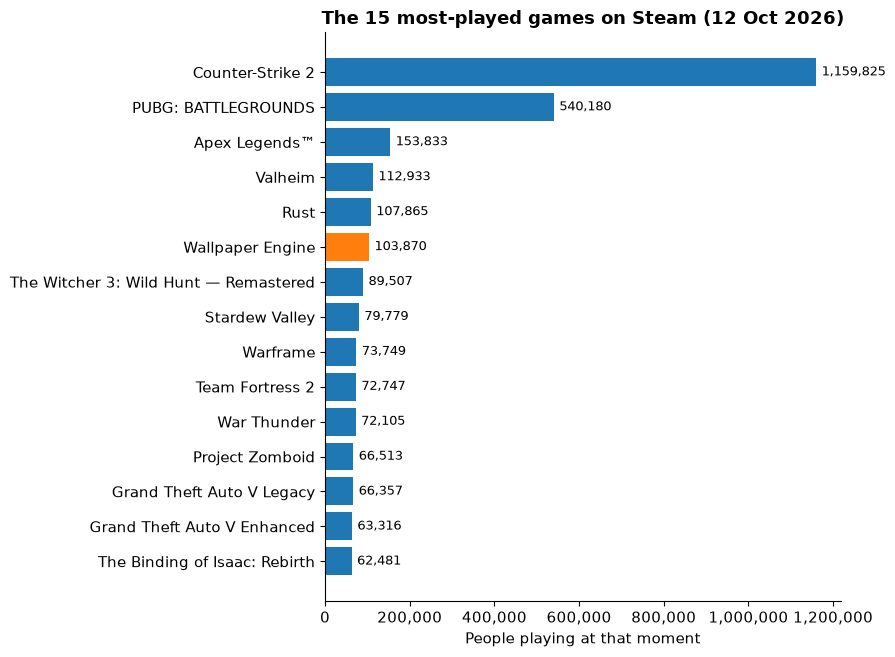

In [2]:
top15 = games.nlargest(15, "players").set_index("game_name")["players"]
hbar(top15, "The 15 most-played games on Steam (12 Oct 2026)", "People playing at that moment", highlight={"Wallpaper Engine"})

**What this means:** a single game holds almost 1 in 5 of all players we tracked. Being in the top 15 means six-figure crowds; most games aren't close.

## 2. How spread out are the players?

Rank all 1,029 games from most to least played and keep a running total. The line shows what share of all players the top games account for.

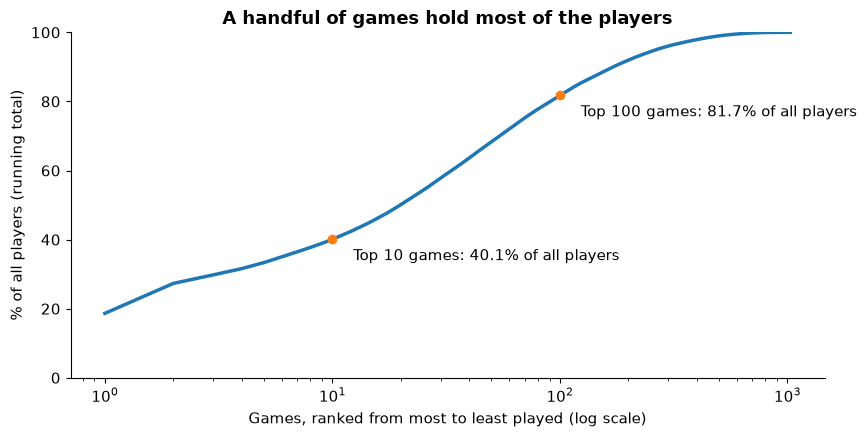

Top 10 share: 40.1%   Top 100 share: 81.7%
Typical (median) game: 417 players.  Games under 1,000 players: 657 of 1029


In [3]:
c = concentration(games)
plot_concentration(c)
print(f"Top 10 share: {c.loc[9,'share']:.1%}   Top 100 share: {c.loc[99,'share']:.1%}")
print(f"Typical (median) game: {games['players'].median():,.0f} players.  Games under 1,000 players: {(games['players']<1000).sum()} of {len(games)}")

The **top 10 games hold 40.1%** of all players, and the top 100 hold 81.7%. The typical game in this list (which is already the most-owned 1,000 on Steam) has only **417** people playing, and 657 of the 1,029 have fewer than 1,000.

**What this means:** attention on Steam is a "winner takes most" market. Even popular games usually have small, steady crowds, so a game studio should plan for a niche, not a hit.

## 3. Do free games attract more players than paid ones?

*Free-to-play* = free to download; the game earns money from optional in-game purchases. You might expect free games to win easily.

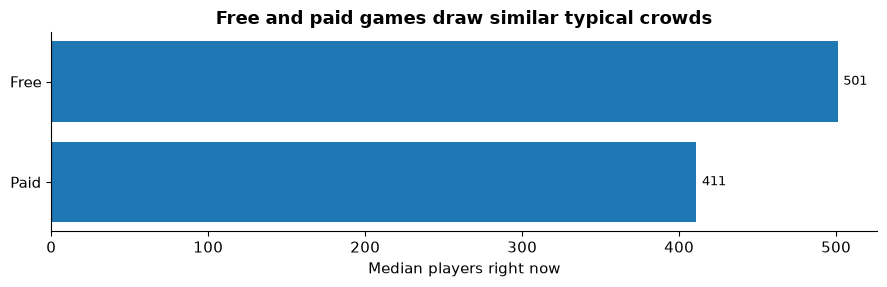

,games,median_players,median_positive_reviews
is_free,,,
Free,151,501.0,0.804
Paid,877,411.0,0.894


In [4]:
t = games.groupby(games["is_free"].map({True: "Free", False: "Paid"})).agg(
    games=("players", "size"), median_players=("players", "median"), median_positive_reviews=("steamspy_positive_share", "median")).round(3)
hbar(t["median_players"], "Free and paid games draw similar typical crowds", "Median players right now")
t

The typical free game has 501 players and the typical paid game has 411 (151 free vs 877 paid games). That gap is small enough to be chance. A statistical test in the analysis folder found no real difference. Paid games do get kinder reviews: about 89% positive vs 80% for free games.

**What this means:** "free" doesn't guarantee a crowd. Paid games keep up on players and make people happier.

## 4. Which genres draw the biggest typical crowds?

Most games list several genres (e.g. "Action, RPG"), so a game can count in more than one bar. Only genres with at least 20 games are shown, and non-game software is left out.

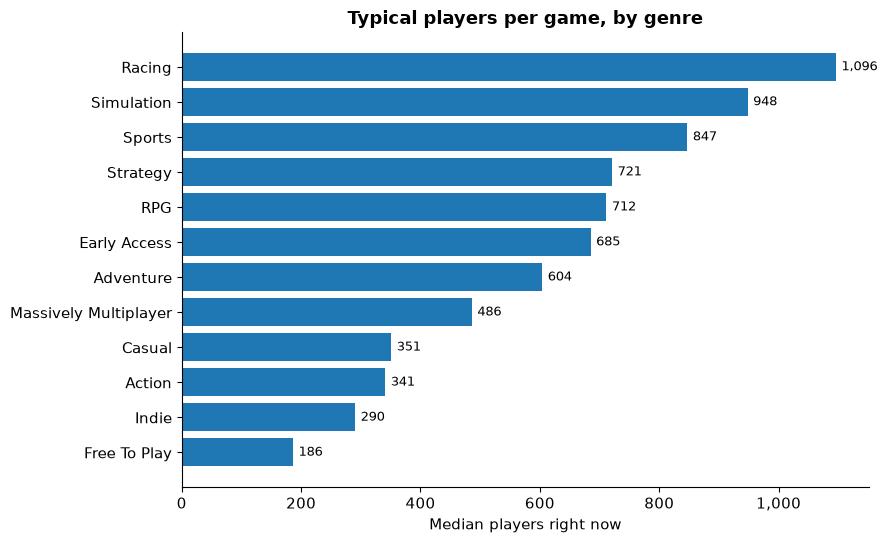

,games,median_players
genres_any,,
Racing,29,1096.0
Simulation,207,948.0
Sports,40,847.0
Strategy,209,721.0
RPG,266,711.5
Early Access,32,685.0
Adventure,391,604.0
Massively Multiplayer,119,486.0
Casual,138,351.0


In [5]:
gm = genre_medians(games)
hbar(gm["median_players"], "Typical players per game, by genre", "Median players right now")
gm

**Racing** (1,096), **Simulation** (948) and **Sports** (847) lead. **Action** (341), **Indie** (290) and **Free To Play** (186) are at the bottom, even though Action has the most games (685) and the biggest hits.

**What this means:** crowded genres like Action have a few giants and lots of quiet games. Smaller genres like Simulation and Racing have fewer games and more players each, which suggests less competition.

## 5. Do people prefer games they can play with others?

*Co-op* = players team up on the same side. *Online co-op* = over the internet; *local co-op* = on the same screen or couch. *PvP* = player vs player.

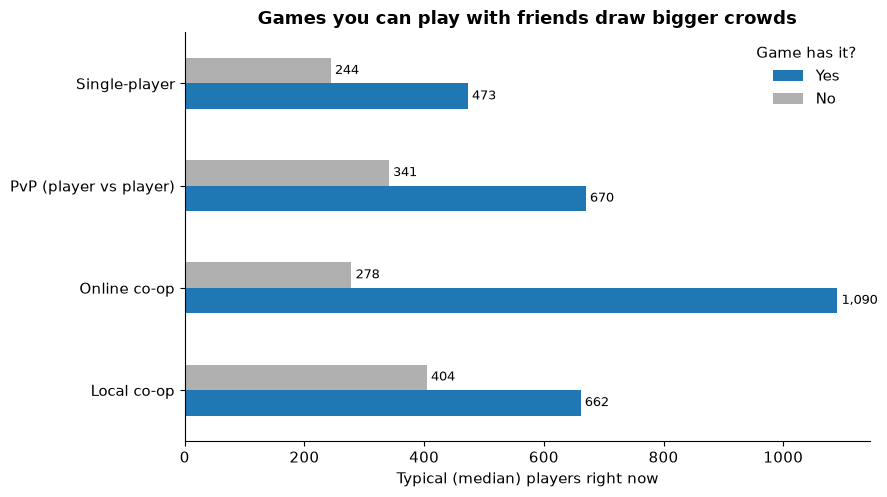

In [6]:
flags = {"Online co-op": "has_online_coop", "Local co-op": "has_local_coop", "PvP (player vs player)": "has_pvp", "Single-player": "is_single_player"}
plot_paired(median_by_flag(games, flags), "Games you can play with friends draw bigger crowds")

Games with **online co-op** have a typical crowd of **1,090** players, almost 4× the 278 for games without it (304 vs 724 games). PvP games also do better (670 vs 341). Local co-op helps less (662 vs 405, and only 112 games have it).

**What this means:** playing *with friends online* is the single feature most linked to a busy game. This shows a link, not proof: big studios may simply be more likely to build online co-op.

## 6. Does the Steam Deck matter?

The **Steam Deck** is Valve's handheld gaming PC. Valve rates each game as *Verified* (works great), *Playable* (works with some fiddling) or *Unsupported*.

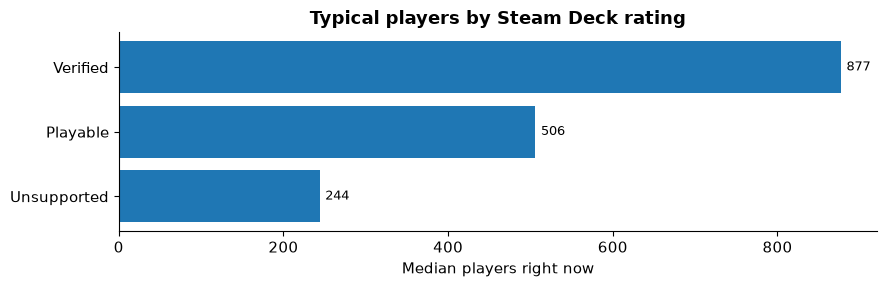

,games,median_players
deck_status,,
Verified,301,877.0
Playable,478,506.0
Unsupported,182,244.0


In [7]:
deck = games[games["deck_status"].isin(["Verified", "Playable", "Unsupported"])]
t = deck.groupby("deck_status")["players"].agg(games="count", median_players="median").reindex(["Verified", "Playable", "Unsupported"])
hbar(t["median_players"], "Typical players by Steam Deck rating", "Median players right now")
t

Verified games have a typical crowd of **877**, Playable 506, Unsupported 244 (301, 478 and 182 games).

**What this means:** games that work well on the handheld also tend to be busier. Again a link, not proof: well-funded games are more likely to get Verified.

## 7. What happens to players after a game launches?

This uses monthly history (2012 to 2026) for 600 of today's popular games where we could see the launch month. Each line shows the typical share of launch-month players still playing *N* months later.

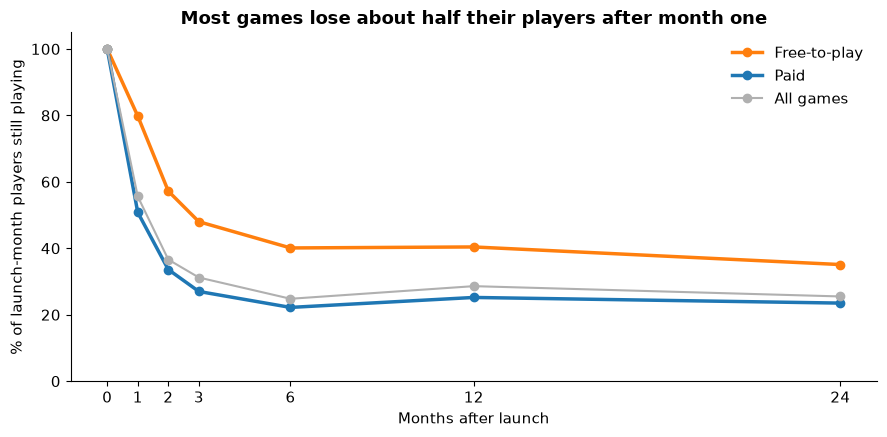

,all,free,paid
months after launch,,,
0,100.0,100.0,100.0
1,56.0,80.0,51.0
2,37.0,57.0,34.0
3,31.0,48.0,27.0
6,25.0,40.0,22.0
12,29.0,40.0,25.0
24,26.0,35.0,24.0


In [8]:
r = retention_table(history())
plot_retention(r)
(r * 100).round(0).rename_axis("months after launch")

The typical game keeps **56%** of its launch-month players after one month (a **44% drop**), 25% after six months, and then *levels off*: still about 26% two years later. Free games hold on better (40% at six months vs 22% for paid).

**What this means:** the first month decides most of a game's future. A game that survives the first few months tends to keep a loyal base for years.

## 8. Do sales bring players back?

This uses daily prices and player counts from 2019 to 2020: **10,756 sales across 1,453 games**. The first week of each sale was compared with similar games that weren't on sale in the same weeks, to strip out things like holidays.

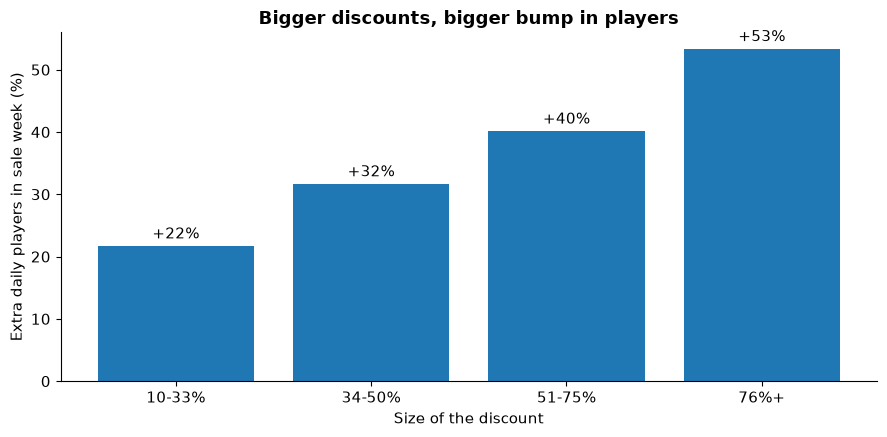

In [9]:
plot_discount(history())

In the first week of a sale, games had about **39% more daily players** than the comparison games. Bigger discounts meant bigger bumps: +22% for 10 to 33% off, up to +53% for 76% off or more.

**What this means:** sales really do bring players back, and deeper discounts work better. Studios choose when to run sales, so treat this as a strong link rather than a guarantee.

## 9. So which games are the "best"?

"Best" combines three things into one score from 0 to 1: **how good the reviews are** (45%), **how many people play** (35%) and **value for money** (20%). Reviews are adjusted so a game with 10 perfect reviews doesn't beat one with 100,000 great ones. Non-game software is excluded, leaving 991 scored games.

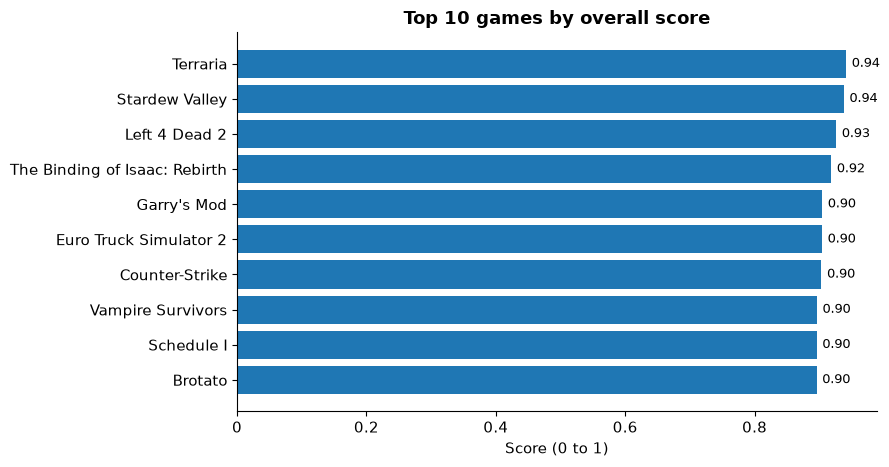

In [10]:
best = games[games["excluded"] == False].nsmallest(10, "composite_rank").set_index("game_name")["composite_score"]
hbar(best, "Top 10 games by overall score", "Score (0 to 1)", fmt="{:.2f}")

**Terraria**, **Stardew Valley**, **Left 4 Dead 2**, **The Binding of Isaac: Rebirth** and **Garry's Mod** top the list. They're all older, cheap, much-loved games that still have big crowds. The interactive **Game Finder** in the app lets you pick categories (e.g. local co-op + strategy) and see the top game for that mix.

**What this means:** the "best" games aren't the newest or most expensive. They're affordable games people keep coming back to for years.

## Summary: what we learned

1. **Winner takes most.** 6.22M people were playing; the top 10 games held 40.1%, and the typical game had just 417.
2. **Free isn't a magic ticket.** Free and paid games draw similar crowds; paid games review better.
3. **Social games are busier.** Online co-op games have almost 4× the typical crowd.
4. **The first month is make-or-break.** Games lose about 44% of players after month one, then level off.
5. **Sales work.** About +39% players in sale week, more for deeper discounts.
6. **The best games are cheap, old favourites**, led by Terraria and Stardew Valley.

## Limitations (in plain words)

- **One day of live data.** The live counts are four snapshots from a single morning (12 Oct 2026). Weekends, holidays and big updates change the picture. The pipeline collects every 6 hours, so this gets stronger over time.
- **Links, not proof.** Most findings show that two things go together, not that one causes the other.
- **Only today's popular games.** The history looks at games that are still popular, so games that launched and flopped are missing. That makes survival look better than it is.
- **The sales data is older** (2019 to 2020); there's no free source of price history after that.
- **Review counts and owner numbers from SteamSpy are estimates**, not official Valve figures.

*Data: Valve Steam Web API and store; SteamSpy.com; SteamCharts.com; Vihanga et al., Mendeley Data (CC BY 4.0). Not affiliated with Valve.*